# Pima Diabetes Classification Pipeline
EDA, feature engineering, resampling, and comparison of nine classifiers.

Run cells in order in Kaggle, Colab, or Jupyter. Set `DATA_PATH` to your CSV location; in Kaggle attach the dataset first, and in Colab upload the CSV.

This version fits median imputation and scaling on training data only and clones models for each experiment. The test-set ranking is exploratory: use cross-validation on training data for model selection and a separate untouched test set for a final performance estimate. Engineered categories are illustrative predictors, not diagnostic criteria. Synthetic resampling treats these category codes as numeric.


## 1. Install dependencies
Restart the kernel if the environment requests it after installation.

In [1]:
%pip install -q imbalanced-learn seaborn matplotlib scikit-learn pandas numpy


Installing packages through the IPython console doesn't work reliably in Spyder. Please use a system terminal to do that, i.e. cmd.exe on Windows, Terminal on macOS or xterm on Linux.


## 2. Import libraries

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE, SVMSMOTE
from imblearn.combine import SMOTEENN, SMOTETomek
sns.set_theme(style="whitegrid")

# Set the output directory path
OUTPUT_DIR = Path("E:\AI Part2\Lect.#4")
OUTPUT_DIR.mkdir(exist_ok=True)
def save_show(name):
    plt.savefig(OUTPUT_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE, SVMSMOTE
from imblearn.combine import SMOTEENN, SMOTETomek
sns.set_theme(style="whitegrid")

# Set the output directory path
OUTPUT_DIR = Path("/kaggle/working/pima_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
def save_show(name):
    plt.savefig(OUTPUT_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()


FileNotFoundError: [WinError 3] The system cannot find the path specified: '\\kaggle\\working\\pima_outputs'

## 3. Load and inspect the raw dataset

# 3-1 Read the dataset and check that it is exist

In [5]:
DATA_PATH = Path("/kaggle/input/datasets/hanyelghaish/diabetes-datasets/NIDDK_Pima__.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError("Update DATA_PATH to the actual location of NIDDK_Pima__.csv.")
else:
    df = pd.read_csv(DATA_PATH)
    df.columns = df.columns.str.strip()
    print(df.columns)

FileNotFoundError: Update DATA_PATH to the actual location of NIDDK_Pima__.csv.

# 3-2: check that the required input columns X: ( 8 variables) and the target Column Y( One variable) is exist in the dataset

In [31]:

# Check that the dataset columns are exist
baseline_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
required = baseline_cols + ["Outcome"] # Input Columns (8 Columns) and the Taget Column( Output: Outcome)
missing = set(required) - set(df.columns) # CHECK the difference between the set of required columns(base columns + Outcome) and the dataset colums

if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
else:
    # Create dataframe that consist of all 9 columns ( 8 Input and 1 Output)
    df = df[required].apply(pd.to_numeric, errors="raise")


# Check that the output Y is exist 
#Y:  donot contains missing values or 
# Y: donot contain values rather than 0 or 1
if df["Outcome"].isna().any() or set(df["Outcome"].unique()) != {0, 1}:
    raise ValueError("Outcome must contain both 0 and 1, with no missing labels.")

# 4- Display some data Statistics

In [32]:
print("Dataset shape:", df.shape)

display(df.head())  # print 5 rows of the dataset
display(df.describe().T) # Print all the dataset statistics (min, , max, mean, standard devision) in each Input and output variables
display(df.isna().sum().rename("Missing values").to_frame()) # Create frame of the number of missing values of each columns
print("Exact duplicate rows:", df.duplicated().sum()) # Check if the data contains duplicate rows
print("Class counts:")                      
print(df["Outcome"].value_counts().sort_index()) # Compute the count of samples in each output class


Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


,Missing values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Exact duplicate rows: 0
Class counts:
Outcome
0    500
1    268
Name: count, dtype: int64


## 4. Raw-data exploration and Data Visualization
These full-dataset plots are descriptive. Do not use the held-out data to tune feature choices.

**(1): Plotting the data Distribtion ( Number of samples that has diapetic or no diapetic and display the values exist in each feature and check the display the rang of the features that has diabetic and the other range that has no diabetic**

# 1-Plot: Data Distriution ( for loop in 8 features) and Dataset

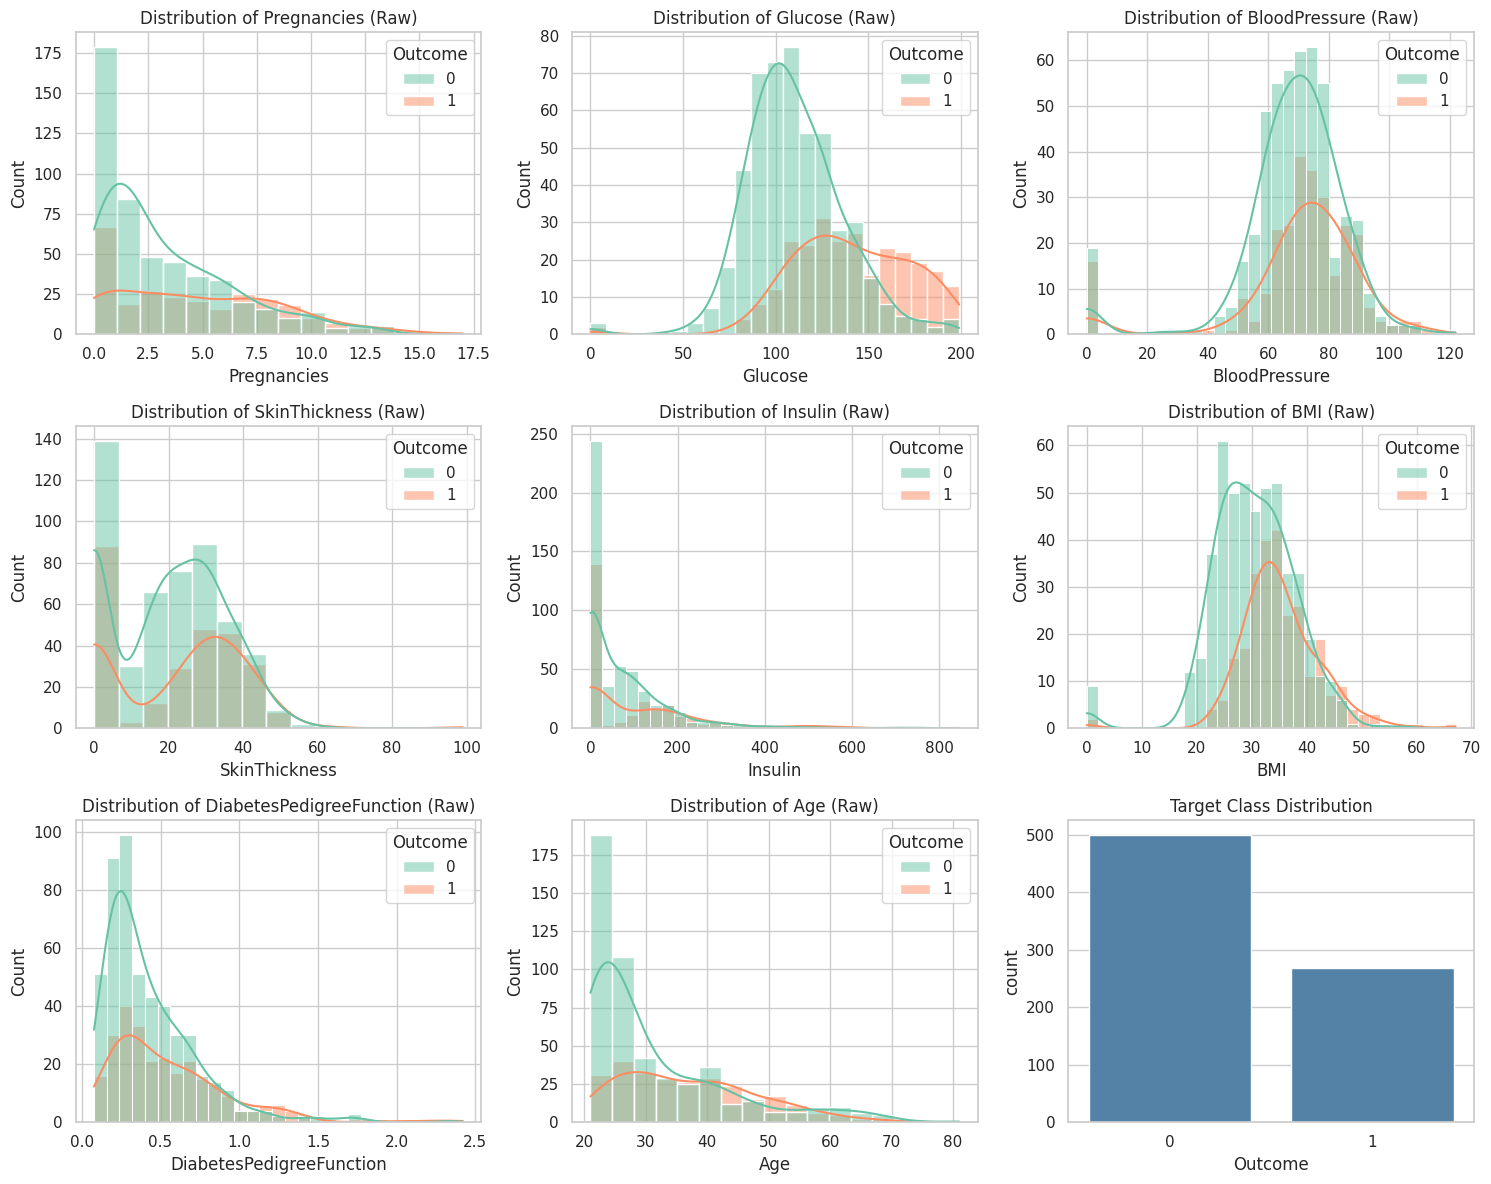

In [33]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()
for idx, col in enumerate(baseline_cols):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, ax=axes[idx], palette="Set2")
    axes[idx].set_title(f"Distribution of {col} (Raw)")
    
sns.countplot(data=df, x="Outcome", ax=axes[-1], color="steelblue")
axes[-1].set_title("Target Class Distribution")
plt.tight_layout()
save_show("01_raw_distributions.png") # Save the Figure

# 2- Plot the box plot ( min, max,  mean , standard deviation and the outliers)

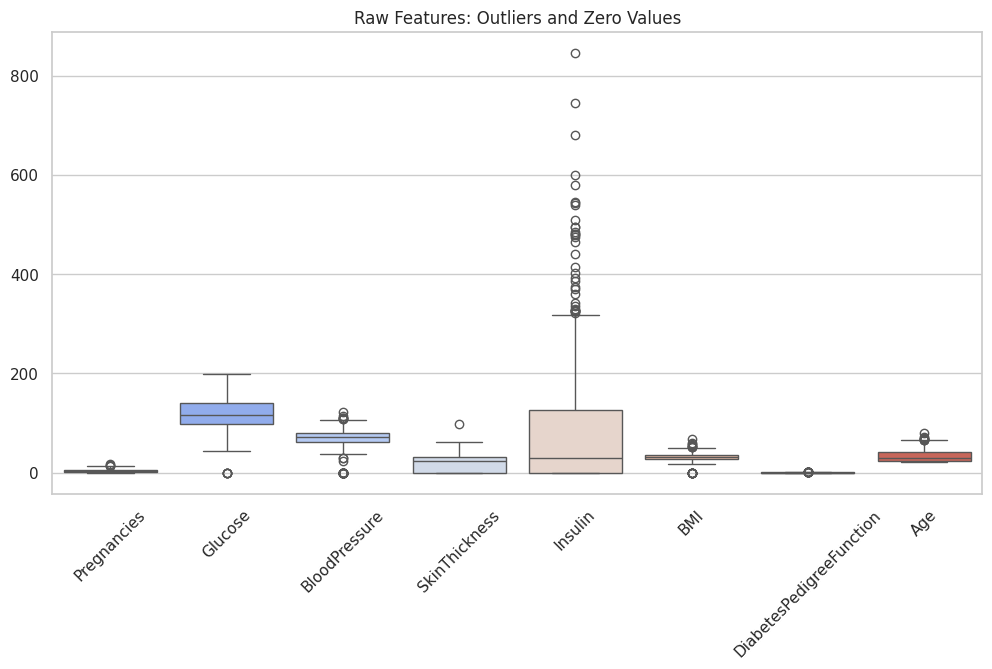

In [34]:

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[baseline_cols], palette="coolwarm")
plt.xticks(rotation=45)
plt.title("Raw Features: Outliers and Zero Values")
save_show("02_raw_boxplots.png")


# 3- Plot the correlation Heatmap between features

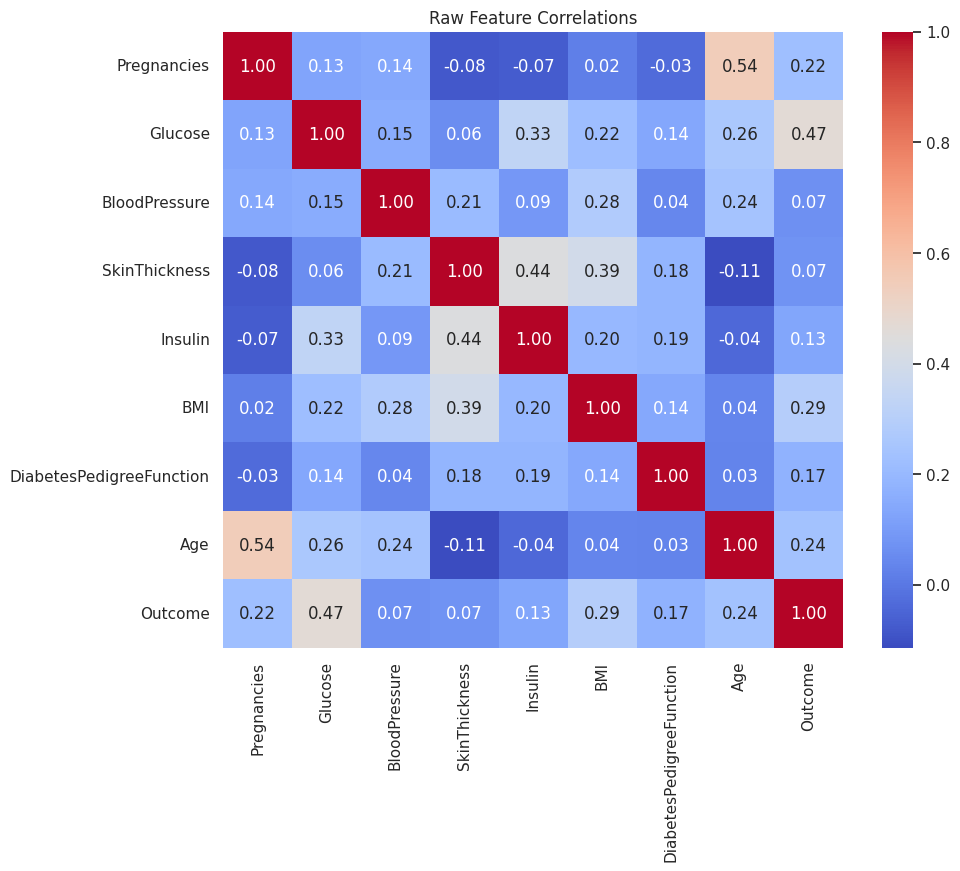

In [35]:

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Raw Feature Correlations")
save_show("03_raw_correlations.png")


## 5. Replace invalid zeros and split: Some Feature contains Zeros which is Wrong
Zero values in the five physiological measurements below are treated as missing. Pregnancy count may legitimately be zero. Median values are learned in Cell 7, after splitting.

**clean_df: a dataframe that we will work after replacing Zero with missing values**

In [36]:
zero_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
clean_df = df.copy()
clean_df[zero_missing_cols] = clean_df[zero_missing_cols].replace(0, np.nan)
display(clean_df.isna().sum().rename("Missing after zero replacement").to_frame())


# We will use the median imputer to fill the missing values (nan) we made before


,Missing after zero replacement
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


# 5- 2: Spiltting Data ( Training and Testing)

1. Trainig Data: X_train_raw, y_train
2. Testing Data:  X_test_raw, y_test

In [37]:
 X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    clean_df[baseline_cols], clean_df["Outcome"], test_size=0.2,
    stratify=clean_df["Outcome"], random_state=42
)

print("Training Shape:", X_train_raw.shape)
print("Testing Shape:", X_test_raw.shape)

Training Shape: (614, 8)
Testing Shape: (154, 8)


## 7. Training-only imputation and scaling
Both feature sets use the same held-out patients. Test values may fall outside [0, 1] when outside the training range.

In [38]:
# We will use the median imputer to fill the missing values (nan) we made before
imputer = SimpleImputer(strategy="median")

# Apply the imputer to the training and testing Samples
train_imputed = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=baseline_cols, index=X_train_raw.index)
test_imputed = pd.DataFrame(imputer.transform(X_test_raw), columns=baseline_cols, index=X_test_raw.index)

print("Training Samples Imputed Shape:", train_imputed.shape)
print("Testing Samples Imputed Shape:", test_imputed.shape)

Training Samples Imputed Shape: (614, 8)
Testing Samples Imputed Shape: (154, 8)


# 8- Preparing Data by Applying the base 8 Features and the Feature Engineering

## 8.1 Define feature engineering
Interactions and fixed bins are added after imputation. Infinite end boundaries prevent out-of-range measurements from becoming missing.
**Create New Features by this function as Handcrafted Features Engineering**

The Dataset becomes:
* **train_imputed** for training data
* **test_imputed** for testing data

# We have two feature modes: baseline (8 features) + feature Engineering (new Features we added to the baselines)

***Function engineer_features(X) to add handcrafted features***

In [39]:
def engineer_features(X):
    X = X.copy()
    X["Glucose_BMI"] = X["Glucose"] * X["BMI"]
    X["Age_BMI"] = X["Age"] * X["BMI"]
    X["Insulin_Glucose"] = X["Insulin"] / (X["Glucose"] + 1e-5)
    X["BMI_Category"] = pd.cut(X["BMI"], bins=[-np.inf, 18.5, 25, 30, np.inf], right=False, labels=[0, 1, 2, 3]).astype(float)
    X["Glucose_Category"] = pd.cut(X["Glucose"], bins=[-np.inf, 100, 126, np.inf], right=False, labels=[0, 1, 2]).astype(float)
    return X


# 8-2: Prepare_data: Dataset with two Feature mode: baseline, Engineering

# prepared_data[feature_mode] = ( Traing_Data, Testing_Data)

In [40]:
prepared_data = {}
scalers = {} # if we have different scalers 
for feature_mode in ["Baseline", "Engineered"]:
    # 1- In case of Base Features
    train_features = train_imputed.copy() # copy the trained imputed data in train_features
    test_features = test_imputed.copy() # copy the test imputed data in test_features

    # or 2- In case of Engineering we add new features to the dataset by call engineer_features functions
    if feature_mode == "Engineered":
        train_features = engineer_features(train_features)
        test_features = engineer_features(test_features)

    
    
    # Apply the Min-Max Scaller on the Prepared data ( Training and Testing)
    scaler = MinMaxScaler()
    # Prepared data specified by feature mode
    prepared_data[feature_mode] = (scaler.fit_transform(train_features), scaler.transform(test_features))
    
    scalers[feature_mode] = scaler
    
    print(feature_mode, " : Prepared training shape:", prepared_data[feature_mode][0].shape)
 

Baseline  : Prepared training shape: (614, 8)
Engineered  : Prepared training shape: (614, 13)


# 8-3: Printing the dataset header and 5 rows of it when Feature Engineering is used

In [41]:
# display the dataset when Feature Engineering is added
print("=========================================")
display(engineer_features(train_imputed).head())
print("=========================================")


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Glucose_BMI,Age_BMI,Insulin_Glucose,BMI_Category,Glucose_Category
353,1.0,90.0,62.0,12.0,43.0,27.2,0.580,24.0,2448.0,652.8,0.477778,2.0,0.0
711,5.0,126.0,78.0,27.0,22.0,29.6,0.439,40.0,3729.6,1184.0,0.174603,2.0,2.0
373,2.0,105.0,58.0,40.0,94.0,34.9,0.225,25.0,3664.5,872.5,0.895238,3.0,1.0
46,1.0,146.0,56.0,29.0,125.0,29.7,0.564,29.0,4336.2,861.3,0.856164,2.0,2.0
682,0.0,95.0,64.0,39.0,105.0,44.6,0.366,22.0,4237.0,981.2,1.105263,3.0,0.0


## 9. Define six resampling methods and nine Machine Learning classifiers

In [42]:
resampling_methods = {
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42),
    "BorderlineSMOTE": BorderlineSMOTE(random_state=42),
    "SVMSMOTE": SVMSMOTE(random_state=42),
    "SMOTEENN": SMOTEENN(random_state=42),
    "SMOTETomek": SMOTETomek(random_state=42)
}
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
    "ExtraTrees": ExtraTreesClassifier(random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "NaiveBayes": GaussianNB()
}


## 10. Train and compare 108 experiments

# Only training data are resampled. 

In [43]:
results = []
trained_models = {}

for feature_mode, (X_tr, X_te) in prepared_data.items(): # 2 feature mode: Baseline and Engineering
   
    #  Resampleing Method: SMOTE, ADASYN, BorderlineSMOTE, SVMSMOTE, SMOTEENN, SMOTETomek
    for sname, sampler in resampling_methods.items(): # 6 resampling methods

        # Working on Training Data (X_tr, y_train)
        Xr, yr = clone(sampler).fit_resample(X_tr, y_train)
        print(feature_mode, sname, "resampled shape:", Xr.shape)

        # Applying 9 ML teching: LR, KNN, DT, SVM, RF, ET, GB,AdaBoost, NaiveBayes
        for mname, prototype in models.items(): # Apply 9 ML mode
            model = clone(prototype)
            # Traing the model
            model.fit(Xr, yr)
            #Test the model
            yp = model.predict(X_te)

            # Collect the results
            positive_index = list(model.classes_).index(1)
            prob = model.predict_proba(X_te)[:, positive_index]
            auc = roc_auc_score(y_test, prob)

            # save the results into list
            key = f"{feature_mode}_{sname}_{mname}"
            trained_models[key] = {"model": model, "y_test": y_test.copy(), "y_pred": yp.copy(), "y_prob": prob.copy()}
            results.append([feature_mode, sname, mname,
                accuracy_score(y_test, yp), precision_score(y_test, yp, zero_division=0),
                recall_score(y_test, yp, zero_division=0), f1_score(y_test, yp, zero_division=0), auc])

# Printing the results
results_df = pd.DataFrame(results, columns=["Feature_Set", "Resampling", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"])
results_df.sort_values("Accuracy", ascending=False, inplace=True)
display(results_df.head(20))

# Save the results in CSV file
results_df.to_csv(OUTPUT_DIR / "Results.csv", index=False)

# Display the comparison report
fe_comparison = results_df.groupby("Feature_Set")[["Accuracy", "F1", "ROC_AUC"]].mean()
print("Feature engineering comparison (exploratory averages):")
display(fe_comparison)
# save it 
fe_comparison.to_csv(OUTPUT_DIR / "Feature_Engineering_Comparison.csv")


Baseline SMOTE resampled shape: (800, 8)
Baseline ADASYN resampled shape: (801, 8)
Baseline BorderlineSMOTE resampled shape: (800, 8)
Baseline SVMSMOTE resampled shape: (800, 8)
Baseline SMOTEENN resampled shape: (491, 8)
Baseline SMOTETomek resampled shape: (772, 8)
Engineered SMOTE resampled shape: (800, 13)
Engineered ADASYN resampled shape: (784, 13)
Engineered BorderlineSMOTE resampled shape: (800, 13)
Engineered SVMSMOTE resampled shape: (800, 13)
Engineered SMOTEENN resampled shape: (470, 13)
Engineered SMOTETomek resampled shape: (768, 13)


,Feature_Set,Resampling,Model,Accuracy,Precision,Recall,F1,ROC_AUC
31,Baseline,SVMSMOTE,RandomForest,0.772727,0.661017,0.722222,0.690265,0.818519
79,Engineered,BorderlineSMOTE,AdaBoost,0.772727,0.633803,0.833333,0.720000,0.830833
22,Baseline,BorderlineSMOTE,RandomForest,0.759740,0.634921,0.740741,0.683761,0.824907
2,Baseline,SMOTE,DecisionTree,0.753247,0.648148,0.648148,0.648148,0.729074
33,Baseline,SVMSMOTE,GradientBoosting,0.753247,0.637931,0.685185,0.660714,0.822407
76,Engineered,BorderlineSMOTE,RandomForest,0.753247,0.625000,0.740741,0.677966,0.842778
47,Baseline,SMOTETomek,DecisionTree,0.753247,0.642857,0.666667,0.654545,0.733333
4,Baseline,SMOTE,RandomForest,0.753247,0.633333,0.703704,0.666667,0.815370
88,Engineered,SVMSMOTE,AdaBoost,0.753247,0.614286,0.796296,0.693548,0.815093
25,Baseline,BorderlineSMOTE,AdaBoost,0.746753,0.608696,0.777778,0.682927,0.841296


Feature engineering comparison (exploratory averages):


,Accuracy,F1,ROC_AUC
Feature_Set,,,
Baseline,0.719336,0.641766,0.790907
Engineered,0.722583,0.651667,0.803735


## 11. Confusion matrices and ROC curves for the four highest test accuracies
These are exploratory rankings on a shared test set, not an unbiased estimate of the selected winner.

# PLoT figures

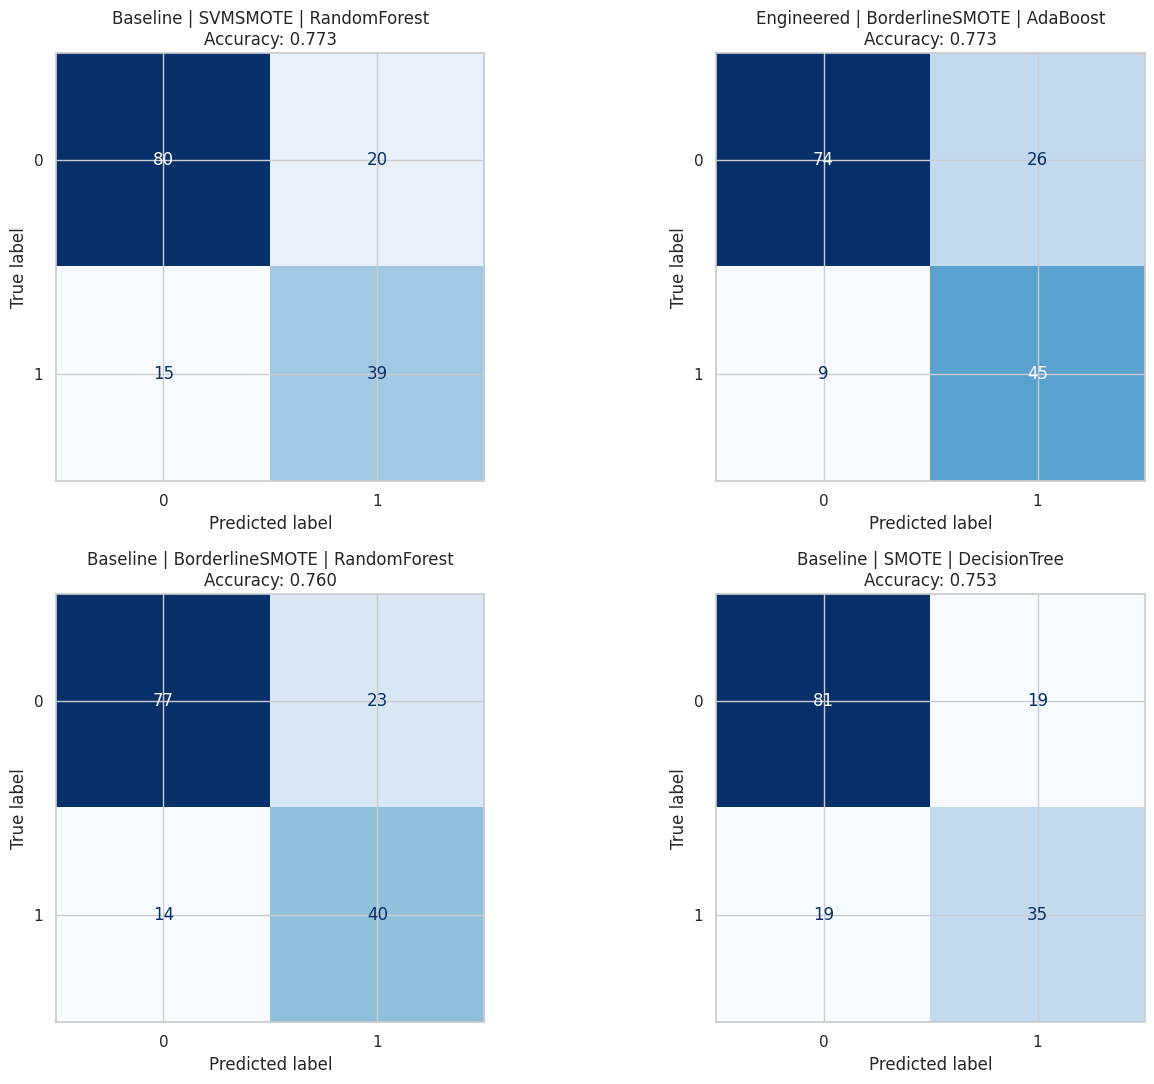

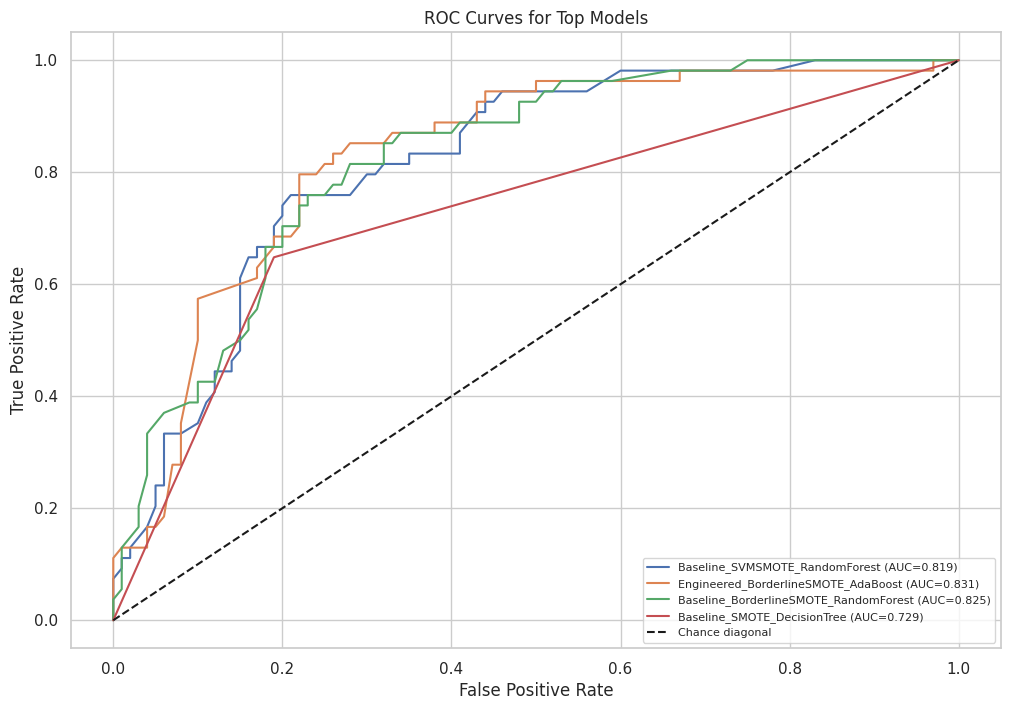

Results and figures saved to: /kaggle/working/pima_outputs


In [44]:
top_results = results_df.head(4)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()
for i, (_, row) in enumerate(top_results.iterrows()):
    key = f"{row['Feature_Set']}_{row['Resampling']}_{row['Model']}"
    m_data = trained_models[key]
    cm = confusion_matrix(m_data["y_test"], m_data["y_pred"], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(ax=axes[i], cmap="Blues", colorbar=False)
    axes[i].set_title(f"{row['Feature_Set']} | {row['Resampling']} | {row['Model']}\nAccuracy: {row['Accuracy']:.3f}")
plt.tight_layout()
save_show("04_top_confusion_matrices.png")
plt.figure(figsize=(12, 8))
for _, row in top_results.iterrows():
    key = f"{row['Feature_Set']}_{row['Resampling']}_{row['Model']}"
    m_data = trained_models[key]
    fpr, tpr, _ = roc_curve(m_data["y_test"], m_data["y_prob"])
    plt.plot(fpr, tpr, label=f"{key} (AUC={row['ROC_AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance diagonal")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Top Models")
plt.legend(loc="lower right", fontsize=8)
save_show("05_top_roc_curves.png")
print("Results and figures saved to:", OUTPUT_DIR.resolve())
